In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone

assert ".venv" in sys.executable, "Wrong kernel! Switch to 'Python (f1-tyre-strategy)' (top right)."
PROJECT_ROOT = Path.cwd().parent
assert PROJECT_ROOT.name == "f1-tyre-strategy-simulator", "Notebook isn't in the notebooks/ folder!"
sys.path.insert(0, str(PROJECT_ROOT / "src"))

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
TARGET = "DeltaToQuali"
DEV_YEARS = [2022, 2023, 2024]   # everything the simulator LEARNS comes from these; 2025 is for back-testing

model = joblib.load(MODELS_DIR / "lap_time_model.joblib")
meta = json.loads((MODELS_DIR / "lap_time_model_meta.json").read_text())
COLS = meta["input_columns"]

laps = pd.read_parquet(PROCESSED_DIR / "laps_all_flags.parquet")
clean = pd.read_parquet(PROCESSED_DIR / "laps_clean.parquet")
clean = clean[clean["TyreAge"].notna()].copy()
for col in ["TyreAge", "GreenFlagTyreLaps", "LapNo", "StintNo", "LapsRemaining", "RaceLaps"]:
    clean[col] = clean[col].astype(float)

print(f"All laps with flags: {len(laps):,} | clean laps: {len(clean):,}")
print("Model:", meta["model"])
print("✅ Ready — simulator ingredients will be learned from", DEV_YEARS)

All laps with flags: 101,291 | clean laps: 67,753
Model: Ridge v7 (v6 + RaceProgress)
✅ Ready — simulator ingredients will be learned from [2022, 2023, 2024]


In [2]:
laps = laps.sort_values(["Year", "Round", "Driver", "LapNumber"]).reset_index(drop=True)

# The driver's NEXT lap, next to each lap (same driver, same race)
next_cols = ["LapNumber", "LapTimeSeconds", "PitOutTime", "StintNo", "IsSafetyCar", "IsVSC", "IsRedFlag"]
nxt = laps.groupby(["Year", "Round", "Driver"])[next_cols].shift(-1).add_prefix("Next_")
for c in ["Next_IsSafetyCar", "Next_IsVSC", "Next_IsRedFlag"]:
    nxt[c] = nxt[c].astype("boolean").fillna(False).astype(bool)   # no FutureWarning
both = pd.concat([laps, nxt], axis=1)

# A real tyre stop: an in-lap, followed directly by an out-lap that starts a NEW stint
is_stop = (
    both["PitInTime"].notna() & both["Next_PitOutTime"].notna()
    & (both["Next_LapNumber"] == both["LapNumber"] + 1)
    & (both["Next_StintNo"] > both["StintNo"])
    & (both["LapNumber"] > 1)
    & ~both["WetRace"].fillna(False).astype(bool)
)
stops = both[is_stop].copy()

# Reference: median lap of drivers NOT pitting on that lap
not_pitting = laps["PitInTime"].isna() & laps["PitOutTime"].isna() & laps["LapTimeSeconds"].notna()
ref = laps[not_pitting].groupby(["Year", "Round", "LapNumber"])["LapTimeSeconds"].median()
stops = stops.join(ref.rename("RefInLap"), on=["Year", "Round", "LapNumber"])
stops = stops.join(ref.rename("RefOutLap"), on=["Year", "Round", "Next_LapNumber"])

# New column: the time lost, compared with drivers who stayed out on the same two laps
stops["PitLoss"] = (stops["LapTimeSeconds"] + stops["Next_LapTimeSeconds"]) - (stops["RefInLap"] + stops["RefOutLap"])

# Condition during the IN-LAP. "Fully" = no green-flag running (code 1) on that lap at all.
status = stops["TrackStatus"].astype(str)
green_part = status.str.contains("1")
full_sc = status.str.contains("4") & ~green_part
full_vsc = (status.str.contains("6") | status.str.contains("7")) & ~green_part & ~status.str.contains("4")
partly = (stops["IsSafetyCar"] | stops["IsVSC"]) & ~full_sc & ~full_vsc
stops["Condition"] = np.select(
    [stops["IsRedFlag"] | stops["Next_IsRedFlag"], full_sc, full_vsc, partly],
    ["Red flag", "Safety car", "VSC", "SC/VSC part of lap"], default="Green",
)
stops["Plausible"] = stops["PitLoss"].between(5, 60)

print(f"Real tyre stops found (dry races): {len(stops):,}")
print(f"Outside 5–60 s (removed as implausible): {(~stops['Plausible']).sum()}")
print("\nStops by condition (2022–24, plausible only):")
dev_stops = stops[stops["Year"].isin(DEV_YEARS) & stops["Plausible"]]
print(dev_stops.groupby("Condition")["PitLoss"].agg(Stops="size", MedianLoss="median").round(2).to_string())

print("\nIn-lap track-status codes among neutralised stops (most common):")
print(stops.loc[stops["IsSafetyCar"] | stops["IsVSC"], "TrackStatus"].value_counts().head(8).to_string())

Real tyre stops found (dry races): 2,690
Outside 5–60 s (removed as implausible): 433

Stops by condition (2022–24, plausible only):
                    Stops  MedianLoss
Condition                            
Green                1532       22.65
SC/VSC part of lap     92       17.06
Safety car             53       22.50
VSC                    36       19.52

In-lap track-status codes among neutralised stops (most common):
TrackStatus
4      167
124    121
24      62
126     53
14      51
45      39
26      38
451     28


In [3]:
# Was the race neutralised (SC or VSC) on each lap? (any driver flagged = the race was)
race_neutral = laps.groupby(["Year", "Round", "LapNumber"])["IsNeutralised"].any()
lap_time = laps.set_index(["Year", "Round", "Driver", "LapNumber"])["LapTimeSeconds"]

rows = []
neutral_stops = stops[stops["Condition"].isin(["Safety car", "VSC", "SC/VSC part of lap"])]
for _, s in neutral_stops.iterrows():
    y, r, d, start = s["Year"], s["Round"], s["Driver"], s["LapNumber"]
    neutral_by_lap = race_neutral.loc[(y, r)]

    # Window: from the in-lap to the restart lap (first lap after the stop with no SC/VSC), max 12 laps
    end = start + 1
    while end in neutral_by_lap.index and neutral_by_lap.loc[end] and end < start + 12:
        end += 1
    window = np.arange(start, end + 1)

    driver_laps = [lap_time.get((y, r, d, lap)) for lap in window]
    ref_laps = [ref.get((y, r, lap)) for lap in window]
    if any(v is None or pd.isna(v) for v in driver_laps + ref_laps):
        continue   # skip stops with a missing lap in the window
    rows.append(dict(Year=y, Round=r, Driver=d, Condition=s["Condition"],
                     WindowLaps=len(window), Loss=sum(driver_laps) - sum(ref_laps)))

window_loss = pd.DataFrame(rows)
window_loss["Plausible"] = window_loss["Loss"].between(-5, 60)
dev_window = window_loss[window_loss["Year"].isin(DEV_YEARS) & window_loss["Plausible"]]

print(f"Neutralised stops measured over the full period: {len(window_loss)} "
      f"({(~window_loss['Plausible']).sum()} implausible removed)")
print("\nNet pit-stop loss by the restart (2022–24):")
print(dev_window.groupby("Condition").agg(Stops=("Loss", "size"), MedianLoss=("Loss", "median"),
                                          MedianWindowLaps=("WindowLaps", "median")).round(2).to_string())
print(f"\nFor comparison — green-flag stop (2-lap measurement): "
      f"{dev_stops.loc[dev_stops['Condition'] == 'Green', 'PitLoss'].median():.2f} s")

Neutralised stops measured over the full period: 266 (59 implausible removed)

Net pit-stop loss by the restart (2022–24):
                    Stops  MedianLoss  MedianWindowLaps
Condition                                              
SC/VSC part of lap     76       14.27               4.0
Safety car             30       14.50               5.5
VSC                    33       15.55               4.0

For comparison — green-flag stop (2-lap measurement): 22.65 s


All-track green pit loss: 22.65 s
Under a safety car a stop costs 64% of a green stop; under a VSC 69%

Green-flag pit loss by circuit (2022–24):
                   Stops  Median   Used
Circuit                                
Spa-Francorchamps    107   18.78  18.78
Montréal              34   19.73  19.73
Miami                 50   19.82  19.82
Melbourne             49   20.92  20.92
Austin                84   20.99  20.99
Spielberg            104   21.24  21.24
Jeddah                25   21.32  21.32
Silverstone           30   21.35  21.35
Budapest             116   21.81  21.81
Suzuka                66   21.96  21.96
São Paulo             71   21.98  21.98
Baku                  40   22.08  22.08
Monaco                 7   20.06  22.65
Barcelona            135   22.97  22.97
Las Vegas             55   23.02  23.02
Zandvoort             59   23.05  23.05
Yas Island            95   23.06  23.06
Shanghai              22   23.12  23.12
Mexico City           61   23.12  23.12
Sakhir        

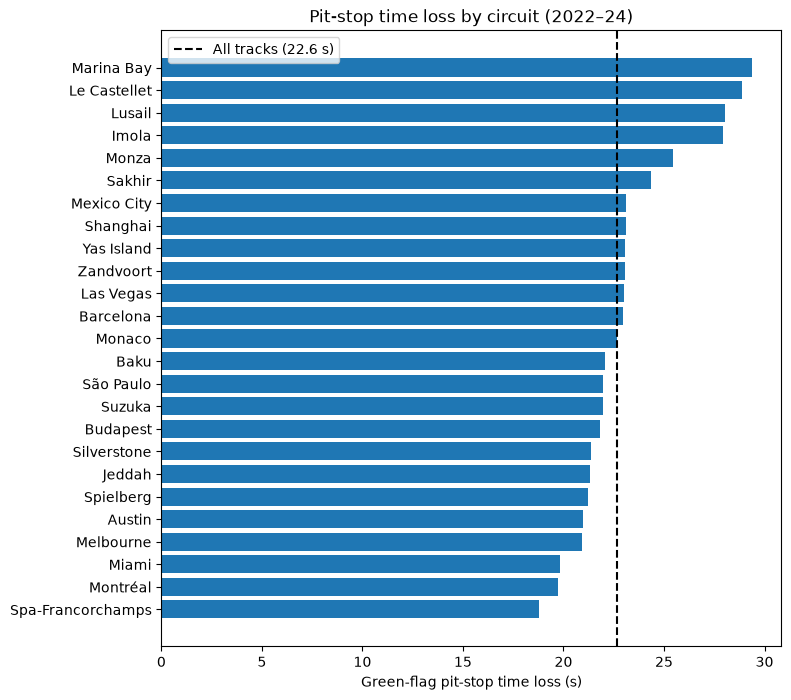

In [4]:
green = dev_stops[dev_stops["Condition"] == "Green"]
global_green = green["PitLoss"].median()

by_circ = green.groupby("Circuit")["PitLoss"].agg(Stops="size", Median="median")
MIN_STOPS = 8
by_circ["Used"] = np.where(by_circ["Stops"] >= MIN_STOPS, by_circ["Median"], global_green)
by_circ = by_circ.sort_values("Used")

# Safety-car and VSC discounts: full neutralised period, fully neutralised in-laps only
factor_sc = dev_window.loc[dev_window["Condition"] == "Safety car", "Loss"].median() / global_green
factor_vsc = dev_window.loc[dev_window["Condition"] == "VSC", "Loss"].median() / global_green
print(f"All-track green pit loss: {global_green:.2f} s")
print(f"Under a safety car a stop costs {factor_sc:.0%} of a green stop; under a VSC {factor_vsc:.0%}")

print("\nGreen-flag pit loss by circuit (2022–24):")
print(by_circ.round(2).to_string())

# Stability check: are 2022–24 estimates close to what happened in 2025? (2025 used only to check)
g25 = stops[(stops["Year"] == 2025) & stops["Plausible"] & (stops["Condition"] == "Green")]
check = by_circ.join(g25.groupby("Circuit")["PitLoss"].median().rename("Median2025"), how="inner")
print(f"\n2025 check on {len(check)} circuits: correlation {check['Used'].corr(check['Median2025']):.2f}, "
      f"average difference {(check['Used'] - check['Median2025']).abs().mean():.2f} s")

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(by_circ.index, by_circ["Used"])
ax.axvline(global_green, color="black", linestyle="--", label=f"All tracks ({global_green:.1f} s)")
ax.set_xlabel("Green-flag pit-stop time loss (s)")
ax.set_title("Pit-stop time loss by circuit (2022–24)")
ax.legend()
fig.savefig(FIG_DIR / "05_pit_loss_by_track.png", dpi=150, bbox_inches="tight")
plt.show()

Correction to add to predicted lap time (s), by tyre age and compound:
Compound   HARD  MEDIUM   SOFT
AgeBand                       
1-5      -0.083  -0.200  0.113
6-10     -0.100  -0.110  0.116
11-15    -0.114   0.015  0.082
16-20    -0.074   0.024  0.069
21-25    -0.025  -0.034  0.258
26-30    -0.046  -0.043  0.000
31-35    -0.219  -0.072  0.000
36+      -0.362  -0.917    NaN

Laps behind each value (corrections need at least 30 ):
Compound    HARD  MEDIUM   SOFT
AgeBand                        
1-5       1518.0  1140.0  321.0
6-10      2057.0  1582.0  424.0
11-15     2088.0  1333.0  302.0
16-20     1878.0  1029.0  176.0
21-25     1423.0   699.0   61.0
26-30     1033.0   385.0   13.0
31-35      690.0   166.0    1.0
36+        987.0   172.0    NaN


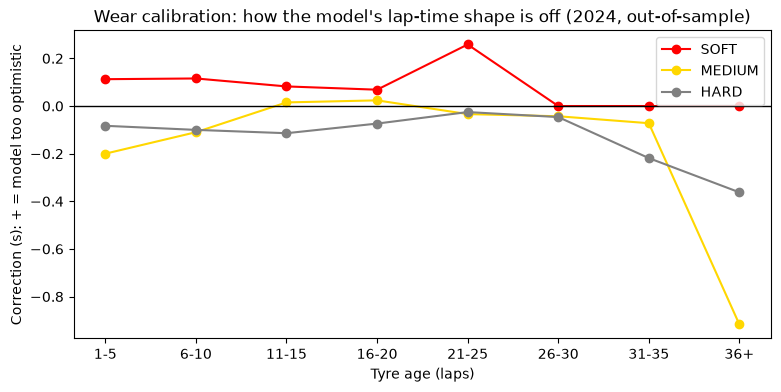

In [5]:
dev = clean[clean["Year"].isin(DEV_YEARS)].copy()
early = dev[dev["Year"] <= 2023]
late = dev[dev["Year"] == 2024].copy()

# Same model settings as the final model, trained only on 2022–23, so 2024 errors are honest
m_early = clone(model).fit(early[COLS], early[TARGET])
late["Resid"] = late[TARGET] - m_early.predict(late[COLS])            # + = real lap slower than predicted
late["ResidWithin"] = late["Resid"] - late.groupby(["Year", "Round", "Driver"])["Resid"].transform("mean")

BANDS = [0, 5, 10, 15, 20, 25, 30, 35, 100]
BAND_LABELS = ["1-5", "6-10", "11-15", "16-20", "21-25", "26-30", "31-35", "36+"]
late["AgeBand"] = pd.cut(late["TyreAge"], BANDS, labels=BAND_LABELS)

tab = (late.groupby(["Compound", "AgeBand"], observed=True)["ResidWithin"]
       .agg(Median="median", Laps="size").reset_index())
MIN_LAPS = 30
tab["Correction"] = np.where(tab["Laps"] >= MIN_LAPS, tab["Median"], 0.0)

calib = tab.pivot(index="AgeBand", columns="Compound", values="Correction").reindex(BAND_LABELS)
print("Correction to add to predicted lap time (s), by tyre age and compound:")
print(calib.round(3).to_string())
print("\nLaps behind each value (corrections need at least", MIN_LAPS, "):")
print(tab.pivot(index="AgeBand", columns="Compound", values="Laps").reindex(BAND_LABELS).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
for comp, colour in {"SOFT": "red", "MEDIUM": "gold", "HARD": "grey"}.items():
    if comp in calib:
        ax.plot(BAND_LABELS, calib[comp].fillna(0).values, marker="o", color=colour, label=comp)
ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("Tyre age (laps)")
ax.set_ylabel("Correction (s): + = model too optimistic")
ax.set_title("Wear calibration: how the model's lap-time shape is off (2024, out-of-sample)")
ax.legend()
fig.savefig(FIG_DIR / "05_wear_calibration.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
dev_laps = laps[laps["Year"].isin(DEV_YEARS)]

# One row per race lap: was a safety car / VSC out on that lap?
race_lap = (dev_laps.groupby(["Year", "Round", "Circuit", "LapNumber"])[["IsSafetyCar", "IsVSC"]]
            .any().reset_index().sort_values(["Year", "Round", "LapNumber"]))
for flag in ["IsSafetyCar", "IsVSC"]:
    prev = race_lap.groupby(["Year", "Round"])[flag].shift(1, fill_value=False)
    race_lap[flag + "Start"] = race_lap[flag] & ~prev          # the lap a new SC / VSC period began
race_lap["RaceLaps"] = race_lap.groupby(["Year", "Round"])["LapNumber"].transform("max")

per_race = race_lap.groupby(["Year", "Round", "Circuit"]).agg(
    HadSC=("IsSafetyCar", "any"), HadVSC=("IsVSC", "any"),
    SCPeriods=("IsSafetyCarStart", "sum"), VSCPeriods=("IsVSCStart", "sum"),
).reset_index()
overall_sc, overall_vsc = per_race["HadSC"].mean(), per_race["HadVSC"].mean()

# Blend: each track's record plus K imaginary "average" races, so 2–3 races can't give 0% or 100%
K = 4
circ = per_race.groupby("Circuit").agg(Races=("HadSC", "size"), SCRaces=("HadSC", "sum"), VSCRaces=("HadVSC", "sum"))
circ["SCProb"] = (circ["SCRaces"] + K * overall_sc) / (circ["Races"] + K)
circ["VSCProb"] = (circ["VSCRaces"] + K * overall_vsc) / (circ["Races"] + K)

print(f"Races 2022–24: {len(per_race)} | had a safety car: {overall_sc:.0%} | had a VSC: {overall_vsc:.0%}")
print(f"Average periods per race: SC {per_race['SCPeriods'].mean():.2f}, VSC {per_race['VSCPeriods'].mean():.2f}")
print("\nBlended chances by circuit (highest SC first):")
print(circ.sort_values("SCProb", ascending=False).round(2).to_string())

# When in the race do safety cars start? (fraction of race distance, 10 bins)
starts = race_lap[race_lap["IsSafetyCarStart"]]
hist, edges = np.histogram(starts["LapNumber"] / starts["RaceLaps"], bins=10, range=(0, 1))
sc_start_probs = hist / hist.sum()
print("\nShare of safety cars starting in each tenth of the race:")
print(" ".join(f"{p:.2f}" for p in sc_start_probs))

Races 2022–24: 68 | had a safety car: 56% | had a VSC: 49%
Average periods per race: SC 0.74, VSC 0.60

Blended chances by circuit (highest SC first):
                   Races  SCRaces  VSCRaces  SCProb  VSCProb
Circuit                                                     
São Paulo              3        3         2    0.75     0.56
Jeddah                 3        3         1    0.75     0.42
Montréal               3        3         2    0.75     0.56
Lusail                 2        2         1    0.71     0.49
Shanghai               1        1         1    0.65     0.59
Le Castellet           1        1         1    0.65     0.59
Austin                 3        2         0    0.61     0.28
Mexico City            3        2         2    0.61     0.56
Suzuka                 3        2         1    0.61     0.42
Silverstone            3        2         1    0.61     0.42
Monaco                 3        2         1    0.61     0.42
Miami                  3        2         2    0.61     

In [7]:
params = {
    "built_from_years": DEV_YEARS,
    "pit_loss_green_by_circuit": {c: round(float(v), 2) for c, v in by_circ["Used"].items()},
    "pit_loss_green_default": round(float(global_green), 2),
    "pit_loss_factor_sc": round(float(factor_sc), 3),
    "pit_loss_factor_vsc": round(float(factor_vsc), 3),
    "wear_calibration_bands": BANDS,
    "wear_calibration_labels": BAND_LABELS,
    "wear_calibration": {comp: {b: round(float(v), 3) for b, v in calib[comp].fillna(0).items()}
                         for comp in calib.columns},
    "sc_prob_by_circuit": {c: round(float(v), 3) for c, v in circ["SCProb"].items()},
    "vsc_prob_by_circuit": {c: round(float(v), 3) for c, v in circ["VSCProb"].items()},
    "sc_prob_default": round(float(overall_sc), 3),
    "vsc_prob_default": round(float(overall_vsc), 3),
    "sc_start_probs_by_tenth": [round(float(p), 3) for p in sc_start_probs],
}
params_path = MODELS_DIR / "strategy_params.json"
params_path.write_text(json.dumps(params, indent=2))
print(f"✅ Saved {params_path.name} ({params_path.stat().st_size / 1e3:.1f} KB)")
print("Circuits with pit-loss values:", len(params["pit_loss_green_by_circuit"]))
print(f"SC factor {params['pit_loss_factor_sc']} | VSC factor {params['pit_loss_factor_vsc']}")

✅ Saved strategy_params.json (3.0 KB)
Circuits with pit-loss values: 25
SC factor 0.64 | VSC factor 0.687


In [8]:
import importlib
import strategy
importlib.reload(strategy)
from strategy import StrategySimulator, race_context, actual_plan, describe_plan, plan_is_simulatable

params = json.loads((MODELS_DIR / "strategy_params.json").read_text())
sim = StrategySimulator(model, params, COLS, calibrate=True)


def get_race(year, circuit):
    r = laps[(laps["Year"] == year) & (laps["Circuit"] == circuit)]
    assert len(r), f"No race found for {year} {circuit}"
    return r


def top10_actual(race_laps, sim, ctx):
    """What the top 10 finishers actually did, and how far their plan was from the best predicted plan."""
    grid = sim.lap_grid(ctx)
    best_time = sim.rank_plans(ctx, start_age=3, top=1)["Time"].iloc[0]
    finishers = (race_laps.drop_duplicates("Driver")[["Driver", "FinishPosition"]]
                 .dropna().sort_values("FinishPosition").head(10))
    rows = []
    for drv, pos in zip(finishers["Driver"], finishers["FinishPosition"]):
        plan, start_age = actual_plan(race_laps[race_laps["Driver"] == drv])
        gap = (sim.plan_time(grid, ctx, plan, start_age) - best_time
               if plan_is_simulatable(plan, ctx["RaceLaps"]) else np.nan)
        rows.append(dict(Pos=int(pos), Driver=drv, Stops=len(plan) - 1,
                         Plan=describe_plan(plan), PredictedGapToBest=gap))
    return pd.DataFrame(rows)


bah = get_race(2024, "Sakhir")
ctx = race_context(bah)
print("Race:", ctx)

best = sim.rank_plans(ctx, start_age=3, top=10)
print("\nTop 10 predicted plans (gap to best, s):")
print(best[["Description", "Stops", "GapToBest"]].round(2).to_string(index=False))

print("\nWhat the top 10 actually did:")
print(top10_actual(bah, sim, ctx).round(2).to_string(index=False))

Race: {'Circuit': 'Sakhir', 'RaceLaps': 57, 'TrackTemp': 22.8, 'AirTemp': 18.1}

Top 10 predicted plans (gap to best, s):
                     Description  Stops  GapToBest
H17 → M20 → H20 (pit lap 17, 37)      2       0.00
H17 → H20 → M20 (pit lap 17, 37)      2       0.00
H18 → H20 → M19 (pit lap 18, 38)      2       0.06
H17 → M19 → H21 (pit lap 17, 36)      2       0.06
H17 → H21 → M19 (pit lap 17, 38)      2       0.06
H18 → M19 → H20 (pit lap 18, 37)      2       0.06
H17 → M21 → H19 (pit lap 17, 38)      2       0.13
H17 → H19 → M21 (pit lap 17, 36)      2       0.13
H16 → H20 → M21 (pit lap 16, 36)      2       0.13
H16 → M21 → H20 (pit lap 16, 37)      2       0.13

What the top 10 actually did:
 Pos Driver  Stops                             Plan  PredictedGapToBest
   1    VER      2 S17 → H20 → S20 (pit lap 17, 37)                4.02
   2    PER      2 S12 → H24 → S21 (pit lap 12, 36)                6.14
   3    SAI      2 S14 → H21 → H22 (pit lap 14, 35)                2.2

In [9]:
checks = [(2024, "Sakhir"), (2024, "Monza"), (2024, "Barcelona"), (2024, "Budapest"), (2023, "Silverstone")]
sim_raw = StrategySimulator(model, params, COLS, calibrate=False)

rows = []
for year, circuit in checks:
    r = get_race(year, circuit)
    ctx_r = race_context(r)
    cal = sim.rank_plans(ctx_r, start_age=3, top=None)
    raw = sim_raw.rank_plans(ctx_r, start_age=3, top=1)
    actual = top10_actual(r, sim, ctx_r)
    best_1 = cal.loc[cal["Stops"] == 1, "Time"].min()
    best_2 = cal.loc[cal["Stops"] == 2, "Time"].min()
    rows.append({
        "Race": f"{year} {circuit}",
        "Best plan (calibrated)": cal["Description"].iloc[0],
        "Best plan (no calibration)": raw["Description"].iloc[0],
        "2-stop minus 1-stop (s)": round(best_2 - best_1, 1),
        "Top-10 most common stops": int(actual["Stops"].mode().iloc[0]),
        "Winner's plan": actual["Plan"].iloc[0],
    })

pd.set_option("display.max_colwidth", 60)
print(pd.DataFrame(rows).to_string(index=False))

            Race           Best plan (calibrated)       Best plan (no calibration)  2-stop minus 1-stop (s)  Top-10 most common stops                    Winner's plan
     2024 Sakhir H17 → M20 → H20 (pit lap 17, 37) M17 → S20 → S20 (pit lap 17, 37)                     -7.7                         2 S17 → H20 → S20 (pit lap 17, 37)
      2024 Monza           H25 → M28 (pit lap 25)           M25 → S28 (pit lap 25)                      5.3                         2           M15 → H38 (pit lap 15)
  2024 Barcelona H20 → M23 → H23 (pit lap 20, 43) M20 → S23 → S23 (pit lap 20, 43)                     -3.0                         2 S17 → M27 → S22 (pit lap 17, 44)
   2024 Budapest H21 → H24 → M25 (pit lap 21, 45) M22 → S24 → S24 (pit lap 22, 46)                     -8.4                         2 M18 → H29 → M23 (pit lap 18, 47)
2023 Silverstone           H24 → M28 (pit lap 24)           M25 → S27 (pit lap 25)                     11.1                         1           M33 → S19 (pit lap 33

In [10]:
SRC = {
    "f1_22_bah": "https://www.formula1.com/en/latest/article/what-tyres-will-the-teams-and-drivers-have-for-the-2022-bahrain-grand-prix.5nQGRrYUMcq8Y2BQeHBTeK",
    "f1_22_aus": "https://www.formula1.com/en/latest/article.what-tyres-will-the-teams-and-drivers-have-for-the-2022-australian-grand.5JMcZHb0xdllgZriDhNh2z.html",
    "f1_22_usa": "https://www.formula1.com/en/latest/article.what-tyres-will-the-teams-and-drivers-have-for-the-2022-united-states-grand.4BgVW4AMaHNwmv0qCaK0rx.html",
    "f1_22_gbr": "https://www.formula1.com/en/latest/article/what-tyres-will-the-teams-and-drivers-have-for-the-2022-british-grand-prix.5NSQn3DvP84qUkQIqltoxd",
    "f1_22_aut": "https://www.formula1.com/en/latest/article/what-tyres-will-the-teams-and-drivers-have-for-the-2022-austrian-grand-prix.ewOLe0OWjT6zjVKJKLyps",
    "f1_22_abu": "https://www.formula1.com/en/latest/article/what-tyres-will-the-teams-and-drivers-have-for-the-2022-abu-dhabi-grand-prix.6JdtRjYzOPcs0ztbRgQ6h",
    "f1tech_22_bel_ned_ita": "https://f1technical.net/news/23803",
    "motorbox_22_aze_can_gbr": "https://www.motorbox.com/auto/sport/f1/news/f1-2022-pirelli-gomme-gp-azerbaijan-canada-gran-bretagna",
    "f1_23_first3": "https://www.formula1.com/en/latest/article.pirelli-confirm-tyre-choices-for-first-three-f1-races-of-2023-as-new.1xlpcTVaLqw0NeM3aYoyCt.html",
    "gpfans_23_season": "https://www.gpfans.com/nl/f1-nieuws/1008416/pirelli-haalt-een-compound-uit-roulatie-voor-formule-1-seizoen-2024/",
    "gpfans_23_hardest_24_jcm": "https://www.gpfans.com/nl/f1-nieuws/1015671/pirelli-maakt-bandencompounds-voor-japan-china-en-miami-bekend/",
    "pirelli_23_hun_bel": "https://press.pirelli.com/tyre-news-and-nominations-for-hungary-and-belgium/",
    "pirelli_23_sin_jpn_qat": "https://press.pirelli.com/unchanged-nominations-for-singapore-japan-and-qatar--in-name-at-least/",
    "f1tech_23_americas": "https://www.f1technical.net/news/24217",
    "pirelli_24_first3": "https://press.pirelli.com/pirelli-nominates-the-compounds-for-the-start-of-2024/",
    "tyrepress_24_imo_mon_can": "https://tyrepress.com/2024/04/pirelli-sticks-with-softest-f1-tyre-compound-trio-for-three-more-grands-prix",
    "f1tech_24_esp_aut_gbr": "https://f1technical.net/news/24701",
    "pirelli_24_hun_bel_ned": "https://press.pirelli.com/all-compounds-on-track-over-next-three-races/",
    "tyrepress_24_ita_aze_sin": "https://www.tyrepress.com/2024/07/soft-september-pirelli-confirms-formula-1-compounds-for-monza-baku-and-singapore/",
    "pirelli_24_americas": "https://press.pirelli.com/these-are-the-tyres-for-the-americas/",
    "msw_25_first5": "https://motorsportweek.com/?p=199909",
    "f1tech_25_mia_imo": "https://www.f1technical.net/news/26579",
    "race24_25_mon_esp_can": "https://www.race24.co.kr/en-us/articles/40449",
    "f1_25_aut": "https://www.formula1.com/en/latest/article/what-tyres-will-the-teams-and-drivers-have-for-the-2025-austrian-grand-prix.7zps1tcBvL2pq421HYW3kT",
    "f1_25_hun": "https://www.formula1.com/en/latest/article/what-tyres-will-the-teams-and-drivers-have-for-the-2025-hungarian-grand-prix.FZNZbRnpwYyLoRBrpOSwL",
    "waterworth_25_gbr": "https://www.benwaterworth.com/post/pirelli-to-trial-radical-tyre-mix-at-belgian-grand-prix",
    "f1tech_25_rest": "https://www.f1technical.net/news/27628",
    "therace_25": "https://www.the-race.com/formula-1/f1-c6-softest-tyre-plans-2025-2026-pirelli/",
}

# (Hard, Medium, Soft) C-numbers as Pirelli published them, plus source key. "Grand Prix" is added below.
NOMS = {
    2022: {"Bahrain": (1, 2, 3, "f1_22_bah"), "Saudi Arabian": (2, 3, 4, "f1_22_usa"),
           "Australian": (2, 3, 5, "f1_22_aus"), "Emilia Romagna": (2, 3, 4, "f1_22_usa"),
           "Miami": (2, 3, 4, "f1_22_usa"), "Spanish": (1, 2, 3, "f1tech_22_bel_ned_ita"),
           "Monaco": (3, 4, 5, "motorbox_22_aze_can_gbr"), "Azerbaijan": (3, 4, 5, "motorbox_22_aze_can_gbr"),
           "Canadian": (3, 4, 5, "motorbox_22_aze_can_gbr"), "British": (1, 2, 3, "f1_22_gbr"),
           "Austrian": (3, 4, 5, "f1_22_aut"), "French": (2, 3, 4, "f1_22_usa"),
           "Hungarian": (2, 3, 4, "f1_22_usa"), "Belgian": (2, 3, 4, "f1tech_22_bel_ned_ita"),
           "Dutch": (1, 2, 3, "f1tech_22_bel_ned_ita"),   # formula1.com says C5 soft: a typo ("three hardest")
           "Italian": (2, 3, 4, "f1tech_22_bel_ned_ita"), "Singapore": (3, 4, 5, "f1_22_abu"),
           "United States": (2, 3, 4, "f1_22_usa"), "Mexico City": (2, 3, 4, "f1_22_usa"),
           "São Paulo": (2, 3, 4, "f1tech_23_americas"), "Abu Dhabi": (3, 4, 5, "f1_22_abu")},
    2023: {"Bahrain": (1, 2, 3, "f1_23_first3"), "Saudi Arabian": (2, 3, 4, "f1_23_first3"),
           "Australian": (2, 3, 4, "f1_23_first3"), "Azerbaijan": (3, 4, 5, "gpfans_23_season"),
           "Miami": (2, 3, 4, "gpfans_23_season"), "Monaco": (3, 4, 5, "gpfans_23_season"),
           "Spanish": (1, 2, 3, "gpfans_23_hardest_24_jcm"), "Canadian": (3, 4, 5, "gpfans_23_season"),
           "Austrian": (3, 4, 5, "gpfans_23_season"), "British": (1, 2, 3, "gpfans_23_hardest_24_jcm"),
           "Hungarian": (3, 4, 5, "pirelli_23_hun_bel"), "Belgian": (2, 3, 4, "pirelli_23_hun_bel"),
           "Dutch": (1, 2, 3, "gpfans_23_hardest_24_jcm"), "Italian": (3, 4, 5, "gpfans_23_season"),
           "Singapore": (3, 4, 5, "pirelli_23_sin_jpn_qat"), "Japanese": (1, 2, 3, "pirelli_23_sin_jpn_qat"),
           "Qatar": (1, 2, 3, "pirelli_23_sin_jpn_qat"), "United States": (2, 3, 4, "f1tech_23_americas"),
           "Mexico City": (3, 4, 5, "f1tech_23_americas"), "São Paulo": (2, 3, 4, "f1tech_23_americas"),
           "Las Vegas": (3, 4, 5, "gpfans_23_season"), "Abu Dhabi": (3, 4, 5, "gpfans_23_season")},
    2024: {"Bahrain": (1, 2, 3, "pirelli_24_first3"), "Saudi Arabian": (2, 3, 4, "pirelli_24_first3"),
           "Australian": (3, 4, 5, "pirelli_24_first3"), "Japanese": (1, 2, 3, "gpfans_23_hardest_24_jcm"),
           "Chinese": (2, 3, 4, "gpfans_23_hardest_24_jcm"), "Miami": (2, 3, 4, "gpfans_23_hardest_24_jcm"),
           "Emilia Romagna": (3, 4, 5, "tyrepress_24_imo_mon_can"), "Monaco": (3, 4, 5, "tyrepress_24_imo_mon_can"),
           "Canadian": (3, 4, 5, "tyrepress_24_imo_mon_can"), "Spanish": (1, 2, 3, "f1tech_24_esp_aut_gbr"),
           "Austrian": (3, 4, 5, "f1tech_24_esp_aut_gbr"), "British": (1, 2, 3, "f1tech_24_esp_aut_gbr"),
           "Hungarian": (3, 4, 5, "pirelli_24_hun_bel_ned"), "Belgian": (2, 3, 4, "pirelli_24_hun_bel_ned"),
           "Dutch": (1, 2, 3, "pirelli_24_hun_bel_ned"), "Italian": (3, 4, 5, "tyrepress_24_ita_aze_sin"),
           "Azerbaijan": (3, 4, 5, "tyrepress_24_ita_aze_sin"), "Singapore": (3, 4, 5, "tyrepress_24_ita_aze_sin"),
           "United States": (2, 3, 4, "pirelli_24_americas"), "Mexico City": (3, 4, 5, "pirelli_24_americas"),
           "São Paulo": (3, 4, 5, "pirelli_24_americas"), "Las Vegas": (3, 4, 5, "therace_25"),
           "Qatar": (1, 2, 3, "f1tech_25_rest"), "Abu Dhabi": (3, 4, 5, "f1tech_25_rest")},
    2025: {"Australian": (3, 4, 5, "msw_25_first5"), "Chinese": (2, 3, 4, "msw_25_first5"),
           "Japanese": (1, 2, 3, "msw_25_first5"), "Bahrain": (1, 2, 3, "msw_25_first5"),
           "Saudi Arabian": (3, 4, 5, "msw_25_first5"), "Miami": (3, 4, 5, "f1tech_25_mia_imo"),
           "Emilia Romagna": (4, 5, 6, "f1tech_25_mia_imo"), "Monaco": (4, 5, 6, "race24_25_mon_esp_can"),
           "Spanish": (1, 2, 3, "race24_25_mon_esp_can"), "Canadian": (4, 5, 6, "race24_25_mon_esp_can"),
           "Austrian": (3, 4, 5, "f1_25_aut"), "British": (2, 3, 4, "waterworth_25_gbr"),
           "Belgian": (1, 3, 4, "f1tech_25_rest"), "Hungarian": (3, 4, 5, "f1_25_hun"),
           "Dutch": (2, 3, 4, "f1tech_25_rest"), "Italian": (3, 4, 5, "f1tech_25_rest"),
           "Azerbaijan": (4, 5, 6, "f1tech_25_rest"), "Singapore": (3, 4, 5, "f1tech_25_rest"),
           "United States": (1, 3, 4, "f1tech_25_rest"), "Mexico City": (2, 4, 5, "therace_25"),
           "São Paulo": (2, 3, 4, "therace_25"), "Las Vegas": (3, 4, 5, "f1tech_25_rest"),
           "Qatar": (1, 2, 3, "f1tech_25_rest"), "Abu Dhabi": (3, 4, 5, "f1tech_25_rest")},
}

REF_DIR = PROJECT_ROOT / "reference"
REF_DIR.mkdir(exist_ok=True)
nom_path = REF_DIR / "pirelli_compounds.csv"

races_tbl = pd.read_parquet(PROCESSED_DIR / "races.parquet").sort_values(["Year", "Round"])
nom = races_tbl[["Year", "Round", "EventName", "Circuit", "WetRace"]].copy()
nom["Needed"] = ~nom["WetRace"].astype(bool)
nom = nom.drop(columns="WetRace")
for col in ["HardC", "MediumC", "SoftC", "Source"]:
    nom[col] = None

for year, events in NOMS.items():
    for short, (h, m, s, key) in events.items():
        mask = (nom["Year"] == year) & (nom["EventName"] == f"{short} Grand Prix")
        assert mask.sum() == 1, f"Event name not found: {year} {short} Grand Prix"
        nom.loc[mask, ["HardC", "MediumC", "SoftC", "Source"]] = [h, m, s, SRC[key]]

nom.to_csv(nom_path, index=False)
print(f"✅ Wrote {nom_path.relative_to(PROJECT_ROOT)}: {nom['SoftC'].notna().sum()} of {len(nom)} races filled")

✅ Wrote reference/pirelli_compounds.csv: 91 of 92 races filled


In [11]:
noms = pd.read_csv(nom_path)
need = noms[noms["Needed"]]
missing = need[need[["HardC", "MediumC", "SoftC"]].isna().any(axis=1)]
done = noms.dropna(subset=["HardC", "MediumC", "SoftC"]).copy()
for c in ["HardC", "MediumC", "SoftC"]:
    done[c] = done[c].astype(int)
bad_order = done[~((done["HardC"] < done["MediumC"]) & (done["MediumC"] < done["SoftC"]))]

print(f"Needed (dry) races: {len(need)} | missing: {len(missing)} | order problems: {len(bad_order)}")
done["Range"] = "C" + done["HardC"].astype(str) + "-C" + done["MediumC"].astype(str) + "-C" + done["SoftC"].astype(str)
print("\nRanges used (all races with data):")
print(done["Range"].value_counts().to_string())
skipped = done[(done["MediumC"] - done["HardC"] > 1) | (done["SoftC"] - done["MediumC"] > 1)]
print("\nRaces with a skipped compound:")
print(skipped[["Year", "EventName", "Range"]].to_string(index=False))
assert len(missing) == 0 and len(bad_order) == 0
print("\n✅ Every needed race has a valid compound range")

Needed (dry) races: 80 | missing: 0 | order problems: 0

Ranges used (all races with data):
Range
C3-C4-C5    38
C2-C3-C4    25
C1-C2-C3    20
C4-C5-C6     4
C1-C3-C4     2
C2-C3-C5     1
C2-C4-C5     1

Races with a skipped compound:
 Year                EventName    Range
 2022    Australian Grand Prix C2-C3-C5
 2025       Belgian Grand Prix C1-C3-C4
 2025 United States Grand Prix C1-C3-C4
 2025   Mexico City Grand Prix C2-C4-C5

✅ Every needed race has a valid compound range


In [12]:
importlib.reload(strategy)
from strategy import (StrategySimulator, TeamChoiceModel, recommend, race_features, race_context,
                      actual_plan, plan_sequence, pit_laps, describe_plan, plan_is_simulatable, LETTER, DRY)
sim = StrategySimulator(model, params, COLS, calibrate=True)

nom_lookup = {(int(r.Year), int(r.Round)): (int(r.HardC), int(r.MediumC), int(r.SoftC))
              for r in noms.dropna(subset=["SoftC"]).itertuples()}
dry_races = races_tbl[~races_tbl["WetRace"].astype(bool)]

rows, race_feats = [], {}
for _, rr in dry_races.iterrows():
    key = (int(rr["Year"]), int(rr["Round"]))
    r = laps[(laps["Year"] == key[0]) & (laps["Round"] == key[1])]
    ctx_r = race_context(r)
    feats = race_features(ctx_r, nom_lookup[key], params)
    race_feats[key] = (ctx_r, feats)
    finishers = (r.drop_duplicates("Driver")[["Driver", "FinishPosition"]]
                 .dropna().sort_values("FinishPosition").head(10))
    for drv, pos in zip(finishers["Driver"], finishers["FinishPosition"]):
        plan, _ = actual_plan(r[r["Driver"] == drv])
        if not plan_is_simulatable(plan, ctx_r["RaceLaps"]):
            continue
        rows.append({"Year": key[0], "Round": key[1], "Circuit": ctx_r["Circuit"], "Driver": drv,
                     "Pos": int(pos), "Plan": plan, "Stops": len(plan) - 1,
                     "Sequence": plan_sequence(plan), "StartCompound": plan[0][0], **feats})
choices = pd.DataFrame(rows)

print(f"Top-10 dry-tyre plans: {len(choices):,} from {choices[['Year', 'Round']].drop_duplicates().shape[0]} races")
print("\nMost common compound orders (all seasons):")
print(choices["Sequence"].value_counts().head(8).to_string())
print("\nStarting compound by how soft Pirelli's range was (share of top-10 drivers):")
print(pd.crosstab(choices["SoftC"], choices["StartCompound"], normalize="index").round(2).to_string())

Top-10 dry-tyre plans: 746 from 79 races

Most common compound orders (all seasons):
Sequence
M-H      223
M-H-H     92
H-M       48
M-H-M     46
M-M-H     30
S-M-S     25
M-S       24
S-H-H     18

Starting compound by how soft Pirelli's range was (share of top-10 drivers):
StartCompound  HARD  MEDIUM  SOFT
SoftC                            
3              0.01    0.49  0.50
4              0.11    0.69  0.21
5              0.14    0.80  0.06
6              0.27    0.73  0.00


In [13]:
def race_level(df):
    """One row per race: the top-10 majority stop count, start compound and compound order, plus the winner."""
    out = []
    for (y, rd), g in df.groupby(["Year", "Round"]):
        mode_stops = int(g["Stops"].value_counts().index[0])
        win = g[g["Pos"] == 1]
        out.append({"Year": y, "Round": rd, "Circuit": g["Circuit"].iloc[0], "ModeStops": mode_stops,
                    "ModeStart": LETTER[g["StartCompound"].value_counts().index[0]],
                    "ModeSequence": g.loc[g["Stops"] == mode_stops, "Sequence"].value_counts().index[0],
                    "WinnerPlan": win["Plan"].iloc[0] if len(win) else None})
    return pd.DataFrame(out)


def history_tables(hist):
    mode = lambda s: s.value_counts().index[0]
    return {"stops_by_circ": hist.groupby("Circuit")["Stops"].agg(mode).to_dict(),
            "seq_by_circ_stops": hist.groupby(["Circuit", "Stops"])["Sequence"].agg(mode).to_dict(),
            "seq_by_stops": hist.groupby("Stops")["Sequence"].agg(mode).to_dict(),
            "global_stops": int(mode(hist["Stops"]))}


def history_sequence(H, circuit, stops):
    return H["seq_by_circ_stops"].get((circuit, stops), H["seq_by_stops"].get(stops))


FEATURE_SETS = {
    "Team choice: Pirelli range only": ["SoftC", "HardMedGap", "MedSoftGap"],
    "Team choice: range + race facts": ["SoftC", "HardMedGap", "MedSoftGap", "RaceLaps", "PitLoss", "TrackTemp"],
    "Team choice: race facts only (no C-numbers)": ["RaceLaps", "PitLoss", "TrackTemp"],
}

train_c, val_c = choices[choices["Year"] <= 2023], choices[choices["Year"] == 2024]
val_r = race_level(val_c)
H = history_tables(train_c)
sim_rank_cache = {}

predictors = {
    "Baseline: most common overall": lambda rr: H["seq_by_stops"].get(rr["ModeStops"]),
    "Baseline: this circuit's history": lambda rr: history_sequence(H, rr["Circuit"], rr["ModeStops"]),
}
print("Top-10 majority number of stops in 2024 races:", val_r["ModeStops"].value_counts().sort_index().to_dict())
outside = val_r[~val_r["ModeStops"].isin([1, 2])]
if len(outside):
    print("Races outside the simulator's 1–2 stop range:",
        [f"{r.Circuit} ({r.ModeStops} stops)" for r in outside.itertuples()])

def sim_only(rr):
    key = (rr["Year"], rr["Round"])
    if key not in sim_rank_cache:
        sim_rank_cache[key] = sim.rank_plans(race_feats[key][0], start_age=3, top=None)
    ranked = sim_rank_cache[key]
    stops = min(max(int(rr["ModeStops"]), 1), 2)        # nearest stop count the simulator searches
    return ranked.loc[ranked["Stops"] == stops, "Sequence"].iloc[0]
predictors["Simulator only (fastest compound order)"] = sim_only
for name, feats_list in FEATURE_SETS.items():
    tm = TeamChoiceModel(feats_list).fit(train_c)
    predictors[name] = (lambda tm: lambda rr: tm.predict_sequence(race_feats[(rr["Year"], rr["Round"])][1],
                                                                  rr["ModeStops"])[0])(tm)

rows = []
for name, fn in predictors.items():
    seqs = val_r.apply(fn, axis=1)
    rows.append({"Method": name,
                 "Start compound correct": (seqs.str[0] == val_r["ModeStart"]).mean(),
                 "Full compound order correct": (seqs == val_r["ModeSequence"]).mean()})
val_table = pd.DataFrame(rows)
print(f"2024 validation: {len(val_r)} dry races (number of stops given, to judge compound choice alone)")
print(val_table.round(2).to_string(index=False))

# Rule written before seeing results: best full-order accuracy among team-choice versions; tie → fewer features
tc = val_table[val_table["Method"].str.startswith("Team choice")].copy()
tc["NFeatures"] = tc["Method"].map(lambda m: len(FEATURE_SETS[m]))
CHOSEN = tc.sort_values(["Full compound order correct", "Start compound correct", "NFeatures"],
                        ascending=[False, False, True]).iloc[0]["Method"]
print(f"\n✅ Chosen by the pre-set rule: {CHOSEN}")

Top-10 majority number of stops in 2024 races: {1: 10, 2: 9, 3: 2}
Races outside the simulator's 1–2 stop range: ['Suzuka (3 stops)', 'Lusail (3 stops)']
2024 validation: 21 dry races (number of stops given, to judge compound choice alone)
                                     Method  Start compound correct  Full compound order correct
              Baseline: most common overall                    0.90                         0.71
           Baseline: this circuit's history                    0.86                         0.67
    Simulator only (fastest compound order)                    0.00                         0.00
            Team choice: Pirelli range only                    0.86                         0.71
            Team choice: range + race facts                    0.90                         0.71
Team choice: race facts only (no C-numbers)                    0.86                         0.67

✅ Chosen by the pre-set rule: Team choice: range + race facts


In [14]:
hist_c = choices[choices["Year"] <= 2024]
team_final = TeamChoiceModel(FEATURE_SETS[CHOSEN]).fit(hist_c)
H_final = history_tables(hist_c)
test_r = race_level(choices[choices["Year"] == 2025])
print(f"2025 dry races: {len(test_r)} — this takes a few minutes")
print("Top-10 majority number of stops in 2025:", test_r["ModeStops"].value_counts().sort_index().to_dict())

rows = []
for _, rr in test_r.iterrows():
    key = (rr["Year"], rr["Round"])
    ctx_r, feats = race_feats[key]
    rec = recommend(sim, team_final, ctx_r, feats, start_age=3, n_sims=200)
    clean_stops = int(sim.rank_plans(ctx_r, start_age=3, top=1)["Stops"].iloc[0])
    hist_stops = int(H_final["stops_by_circ"].get(ctx_r["Circuit"], H_final["global_stops"]))
    win = rr["WinnerPlan"]
    rec_plan = rec["recommended"]["Plan"]
    pit_err = (np.mean(np.abs(np.array(pit_laps(rec_plan)) - np.array(pit_laps(win))))
               if win is not None and len(win) == len(rec_plan) else np.nan)
    rows.append({
        "Rd": rr["Round"], "Circuit": ctx_r["Circuit"],
        "Stops: model": rec["stops"], "Stops: clean only": clean_stops, "Stops: history": hist_stops,
        "Stops: overall": H_final["global_stops"],
        "Stops: top-10": rr["ModeStops"], "Stops: winner": len(win) - 1 if win is not None else np.nan,
        "Order: model": rec["sequence"], "Order: sim only": rec["fastest"]["Sequence"],
        "Order: history": history_sequence(H_final, ctx_r["Circuit"], rec["stops"]),
        "Order: overall": H_final["seq_by_stops"].get(rec["stops"]),
        "Order: top-10": rr["ModeSequence"], "Order: winner": plan_sequence(win) if win is not None else None,
        "Start: top-10": rr["ModeStart"], "Pit-lap error vs winner": pit_err,
        "Model plan": describe_plan(rec_plan), "Cost of team-choice order (s)": rec["cost_vs_fastest"],
    })
    print(f"Done: {ctx_r['Circuit']}")

bt = pd.DataFrame(rows)
print()
print(bt[["Rd", "Circuit", "Stops: model", "Stops: top-10", "Stops: winner", "Order: model",
          "Order: sim only", "Order: top-10", "Order: winner", "Model plan"]].to_string(index=False))

def hit(a, b):
    m = bt[b].notna() & bt[a].notna()
    return (bt.loc[m, a] == bt.loc[m, b]).mean()

def start_hit(a, b="Start: top-10"):
    return (bt[a].str[0] == bt[b]).mean()

summary = pd.DataFrame([
    {"Question": "Number of stops (vs top-10)", "Model": hit("Stops: model", "Stops: top-10"),
     "Simulator only": hit("Stops: clean only", "Stops: top-10"),
     "Circuit history": hit("Stops: history", "Stops: top-10"),
     "Most common overall": hit("Stops: overall", "Stops: top-10")},
    {"Question": "Number of stops (vs winner)", "Model": hit("Stops: model", "Stops: winner"),
     "Simulator only": hit("Stops: clean only", "Stops: winner"),
     "Circuit history": hit("Stops: history", "Stops: winner"),
     "Most common overall": hit("Stops: overall", "Stops: winner")},
    {"Question": "Start compound (vs top-10)", "Model": start_hit("Order: model"),
     "Simulator only": start_hit("Order: sim only"), "Circuit history": start_hit("Order: history"),
     "Most common overall": start_hit("Order: overall")},
    {"Question": "Full compound order (vs top-10)", "Model": hit("Order: model", "Order: top-10"),
     "Simulator only": hit("Order: sim only", "Order: top-10"),
     "Circuit history": hit("Order: history", "Order: top-10"),
     "Most common overall": hit("Order: overall", "Order: top-10")},
])
print("\n2025 BACK-TEST — share of races where each method matched (tested once)")
print(summary.round(2).to_string(index=False))
print(f"\nMedian pit-lap error vs winner (same number of stops): {bt['Pit-lap error vs winner'].median():.1f} laps")
print(f"Median predicted cost of the team-choice order vs the simulator's fastest: "
      f"{bt['Cost of team-choice order (s)'].median():.1f} s")

2025 dry races: 20 — this takes a few minutes
Top-10 majority number of stops in 2025: {1: 11, 2: 7, 3: 1, 5: 1}
Done: Shanghai
Done: Suzuka
Done: Sakhir
Done: Jeddah
Done: Imola
Done: Monaco
Done: Barcelona
Done: Montréal
Done: Spielberg
Done: Budapest
Done: Zandvoort
Done: Monza
Done: Baku
Done: Marina Bay
Done: Austin
Done: Mexico City
Done: São Paulo
Done: Las Vegas
Done: Lusail
Done: Yas Island

 Rd     Circuit  Stops: model  Stops: top-10  Stops: winner Order: model Order: sim only Order: top-10 Order: winner                       Model plan
  2    Shanghai             1              1              1          M-H             H-M           M-H           M-H           M26 → H30 (pit lap 26)
  3      Suzuka             2              1              1        M-H-H           H-M-H           M-H           M-H M16 → H18 → H19 (pit lap 16, 34)
  4      Sakhir             2              2              2        S-H-H           H-M-H         S-M-M         S-M-M S17 → H20 → H20 (pit lap 17, 

In [15]:
neutral_by_race = laps[laps["Year"] == 2025].groupby("Round")["IsNeutralised"].any()
clean_rounds = [rd for rd in test_r["Round"] if not neutral_by_race.get(rd, True)]
print(f"2025 dry races with no SC/VSC at all: {len(clean_rounds)}")

rows = []
for rd in clean_rounds:
    r = laps[(laps["Year"] == 2025) & (laps["Round"] == rd)]
    ctx_r = race_context(r)
    grid = sim.lap_grid(ctx_r)
    finishers = (r.drop_duplicates("Driver")[["Driver", "FinishPosition"]]
                 .dropna().sort_values("FinishPosition").head(10))
    for drv in finishers["Driver"]:
        d = r[r["Driver"] == drv].sort_values("LapNumber")
        plan, start_age = actual_plan(d)
        if not plan_is_simulatable(plan, ctx_r["RaceLaps"]) or d["LapTimeSeconds"].isna().any():
            continue
        lap1_pred = grid[DRY.index(plan[0][0]), min(start_age, grid.shape[1] - 1), 0]
        # Laps 2..N on both sides (the standing start isn't modelled)
        pred = sim.plan_time(grid, ctx_r, plan, start_age) - lap1_pred + d["QualiRef"].iloc[0] * (ctx_r["RaceLaps"] - 1)
        act = d.loc[d["LapNumber"] > 1, "LapTimeSeconds"].sum()
        rows.append({"Circuit": ctx_r["Circuit"], "Driver": drv, "Error (s)": pred - act, "Actual (s)": act})

rt = pd.DataFrame(rows)
rt["Error (%)"] = 100 * rt["Error (s)"] / rt["Actual (s)"]
rt["Error after race offset (s)"] = rt["Error (s)"] - rt.groupby("Circuit")["Error (s)"].transform("mean")
print(f"Drivers compared: {len(rt)}")
print(f"Mean absolute error: {rt['Error (s)'].abs().mean():.1f} s ({rt['Error (%)'].abs().mean():.2f}% of race time)")
print(f"After removing each race's average error: {rt['Error after race offset (s)'].abs().mean():.1f} s")
print(rt.groupby("Circuit")[["Error (s)", "Error (%)"]].mean().round(2).to_string())

2025 dry races with no SC/VSC at all: 6
Drivers compared: 58
Mean absolute error: 50.7 s (1.02% of race time)
After removing each race's average error: 11.0 s
            Error (s)  Error (%)
Circuit                         
Budapest        14.30       0.25
Marina Bay      34.92       0.59
Monza           55.48       1.28
Shanghai        44.51       0.83
Suzuka         128.34       2.65
Yas Island     -17.73      -0.35


In [16]:
APP_DATA = PROJECT_ROOT / "app" / "app_data"     # NOT app/data — .gitignore ignores any folder called data/
APP_DATA.mkdir(parents=True, exist_ok=True)

race_keys = list(race_feats)                       # the 80 dry races (built in Cell 11)
info = races_tbl.set_index(["Year", "Round"])

# 1) One row per race
race_rows = []
for key in race_keys:
    ctx_r, _ = race_feats[key]
    h, m, s = nom_lookup[key]
    race_rows.append({"Year": key[0], "Round": key[1], "EventName": info.loc[key, "EventName"],
                      "Circuit": ctx_r["Circuit"], "RaceLaps": ctx_r["RaceLaps"],
                      "TrackTemp": ctx_r["TrackTemp"], "AirTemp": ctx_r["AirTemp"],
                      "HardC": h, "MediumC": m, "SoftC": s,
                      "Split": info.loc[key, "Split"], "WetQuali": bool(info.loc[key, "WetQuali"])})
app_races = pd.DataFrame(race_rows)

# 2) One row per driver per race, with the plan they actually ran (stored as text, e.g. "MEDIUM:26|HARD:30")
in_app = laps.set_index(["Year", "Round"]).index.isin(race_keys)
app_source = laps[in_app]
drv_rows = []
for (y, rd, drv), d in app_source.groupby(["Year", "Round", "Driver"]):
    plan, start_age = actual_plan(d)
    first = d.sort_values("LapNumber").iloc[0]
    drv_rows.append({"Year": y, "Round": rd, "Driver": drv, "Team": first["Team"],
                     "FinishPosition": first["FinishPosition"], "Status": first["Status"],
                     "QualiRef": first["QualiRef"], "StartAge": start_age,
                     "PlanText": "|".join(f"{c}:{n}" for c, n in plan)})
app_drivers = pd.DataFrame(drv_rows)

# 3) Lap times for the chart
lap_cols = ["Year", "Round", "Driver", "LapNumber", "LapTimeSeconds", "Compound", "TyreAge", "IsNeutralised", "IsClean"]
app_laps = app_source[lap_cols].copy()

for name, frame in [("races", app_races), ("drivers", app_drivers), ("laps", app_laps)]:
    path = APP_DATA / f"{name}.parquet"
    frame.to_parquet(path, index=False)
    print(f"✅ {path.relative_to(PROJECT_ROOT)}: {len(frame):,} rows, {path.stat().st_size / 1e6:.2f} MB")
print("Seasons:", app_races["Year"].value_counts().sort_index().to_dict())

✅ app/app_data/races.parquet: 80 rows, 0.01 MB
✅ app/app_data/drivers.parquet: 1,590 rows, 0.03 MB
✅ app/app_data/laps.parquet: 88,672 rows, 0.41 MB
Seasons: {2022: 18, 2023: 20, 2024: 21, 2025: 21}


In [17]:
team_path = MODELS_DIR / "team_choice_model.joblib"
joblib.dump(team_final, team_path)
reloaded_team = joblib.load(team_path)
key0 = race_keys[0]
assert reloaded_team.predict_sequence(race_feats[key0][1], 1) == team_final.predict_sequence(race_feats[key0][1], 1)
print(f"✅ {team_path.name}: {team_path.stat().st_size / 1e3:.1f} KB | features: {team_final.features}")

✅ team_choice_model.joblib: 2.5 KB | features: ['SoftC', 'HardMedGap', 'MedSoftGap', 'RaceLaps', 'PitLoss', 'TrackTemp']


## Notes & findings – 05 Strategy simulation

**Ingredients (learned from 2022–24 only; 2025 kept for back-testing)**
- Pit loss = driver's in-lap + out-lap minus the median of drivers who didn't pit on those laps. 2,690 real tyre stops in dry races (433 implausible removed).
- Green flag: 22.65 s overall, from Spa 18.8 s to Marina Bay 29.4 s (25 circuits; ≥8 stops each or the overall value). 2025 check: correlation 0.73, average difference 1.37 s.
- Safety car / VSC: the 2-lap measurement showed no discount (22.5 s) because the gain comes as the field bunches. Measured from in-lap to restart: SC 14.5 s (64% of green), VSC 15.6 s (69%).
- Wear calibration (2022–23 model on 2024, per-race offsets removed): softs ≈ +0.1 s/lap slower than predicted, fresh mediums ≈ 0.2 s faster; old tyres faster than predicted (−0.36 hard, −0.92 medium at 36+). Applied only up to 30 laps: very old tyres in the data are survivors (selection bias).
- Safety cars 2022–24: 56% of races had one, 49% a VSC. Track chances blended with 4 average races (e.g. Jeddah 3/3 → 75%, Barcelona 0/3 → 32%). 32% of safety cars start in the first tenth of the race.

**Simulator (`src/strategy.py`)**
- One lap-time grid per race (compound × tyre age × lap); every legal 1–2 stop plan (two-compound rule, stints ≥5 laps) scored in about a second.
- Safety-car-aware ranking: 200 random SC/VSC scenarios per race; a planned stop moves to an SC/VSC starting up to 5 laps earlier, at the reduced cost.
- 2022–24 checks: stop count robust with and without calibration (5/5 races); compound order flipped (all softs vs no softs) → compound choice taken from team behaviour instead.

**Pirelli compound ranges (`reference/pirelli_compounds.csv`)**
- Built from Pirelli / formula1.com / F1Technical sources: 91 of 92 races (all 80 dry races). Ranges: C3–C5 ×38, C2–C4 ×25, C1–C3 ×20, C4–C6 ×4; 4 races skipped a compound. One source typo found (2022 Dutch GP).
- Real pattern: soft starts fall from 50% (SoftC = C3) to 21%, 6% and 0% (C6); hard starts rise from 1% to 27%.

**Team-choice model (chosen on 2024, rule set in advance)**
- 746 top-10 plans from 79 races. Most common: M–H 223, M–H–H 92, H–M 48.
- 2024 (stops given): simulator alone 0% start / 0% order; most common overall 90% / 71%; circuit history 86% / 67%; team choice (range + race facts) 90% / 71% → chosen, but it only ties the simple baseline.

**2025 back-test (20 dry races, tested once)**
- Number of stops: model 60% (vs top-10 and vs winner) against circuit history 30% and most common 35%.
- Misses: Monaco (mandatory two stops in 2025) and Lusail (tyre-life limit) – one-off rules; Montréal – likely FastF1 stint-number glitch (M–H–H–H–H–H); Suzuka, Budapest, Mexico – model chose 2 stops, teams 1 (teams prefer the lower-risk 1-stop when close); Barcelona – 3 stops (not searched). Excluding the rule races and the glitch: 12 of 17.
- Start compound 90% (simulator alone 0%, circuit history 95%, most common 80%). Full order 40% (all baselines 40%); 8 of 12 when the stop count was right.
- Pit laps: median 5 laps from the winner's. Team-choice order costs only 0.4 s vs the simulator's favourite.
- Race time (6 races with no SC/VSC, 58 drivers): 50.7 s average error (1.02%); 11.0 s after removing each race's shared offset. Suzuka +128 s (2.65%), matching its known bias.

**Limitations to state**
- One-off race rules aren't modelled; 1–2 stops only; no risk preference; at most one SC and one VSC per simulated race; compound labels are relative and C-numbers were renumbered between seasons; plans read from FastF1 stint numbers can contain glitches.